# License Plate Detection System

**Tier:** Tier 1 – CORE Project  
**Task:** Object Detection  
**Model:** YOLO  

## Project Goal
The goal of this project is to detect license plates in vehicle images using a YOLO object detection model. The system will identify the location of a license plate and display a bounding box around it.

## Step 1: Dataset Setup (Google Colab)

This project uses the license plate dataset originally obtained from Kaggle. The working dataset has `archive/images/train`, `archive/images/val`, `archive/labels/train`, and `archive/labels/val` folders.

**To reproduce this notebook in a fresh Colab runtime:** upload the dataset ZIP when prompted by the next cell. Colab storage is temporary, so the ZIP must be provided again after a runtime reset. Training requires a GPU (Runtime → Change runtime type → T4 GPU). The existing saved outputs document the completed 20-epoch training; you do **not** need to rerun training just to inspect them.

The trained model (`best.pt`) is saved separately; upload it to Colab if you want to run inference without retraining.

In [ ]:
# Upload the dataset ZIP in a fresh Google Colab session.
# Skip this cell if /content/license_plate_dataset/archive already exists.
from pathlib import Path
import zipfile

archive_dir = Path('/content/license_plate_dataset/archive')
if archive_dir.is_dir():
    print('Dataset already available:', archive_dir)
else:
    from google.colab import files
    uploaded = files.upload()  # Select your license plate dataset ZIP file
    zip_names = [name for name in uploaded if name.lower().endswith('.zip')]
    if not zip_names:
        raise ValueError('Please upload the license plate dataset ZIP file.')
    target = Path('/content/license_plate_dataset')
    target.mkdir(parents=True, exist_ok=True)
    with zipfile.ZipFile(zip_names[0]) as zf:
        zf.extractall(target)
    if not archive_dir.is_dir():
        raise FileNotFoundError('Expected archive/ folder inside dataset ZIP; check ZIP layout.')
    print('Dataset extracted successfully:', archive_dir)

## Step 2: Verify the Dataset Structure

Check the extracted `archive` folder to confirm that the image, label, and configuration files are available.

In [ ]:
import os

dataset_path = '/content/license_plate_dataset/archive'
print('Dataset contents:', os.listdir(dataset_path))

## Step 3: Check Images and Labels

The dataset contains separate folders for images and labels. In this step, the contents of these folders are checked to confirm that the training and validation data are organized correctly.

In [ ]:
import os

archive_path = "/content/license_plate_dataset/archive"

print("Files and folders inside archive:")
print(os.listdir(archive_path))

Files and folders inside archive:
['dataset.yaml', 'classes.txt', 'labels', 'images']


## Step 4: Count Training and Validation Files

The number of training and validation images and their corresponding label files are counted to verify that the dataset is complete and properly organized.

In [ ]:
import os

# Define the dataset folder paths
images_path = "/content/license_plate_dataset/archive/images"
labels_path = "/content/license_plate_dataset/archive/labels"

# Count training and validation files
train_images = os.listdir(images_path + "/train")
val_images = os.listdir(images_path + "/val")

train_labels = os.listdir(labels_path + "/train")
val_labels = os.listdir(labels_path + "/val")

print("Training images:", len(train_images))
print("Training labels:", len(train_labels))
print("Validation images:", len(val_images))
print("Validation labels:", len(val_labels))
print("Total images:", len(train_images) + len(val_images))

Training images: 1526
Training labels: 1526
Validation images: 169
Validation labels: 169
Total images: 1695


## Step 5: Check the Dataset Configuration

The dataset configuration file is reviewed to verify the training and validation paths and the class information required by the YOLO model.

In [ ]:
yaml_path = "/content/license_plate_dataset/archive/dataset.yaml"

with open(yaml_path, "r") as file:
    print(file.read())

train: /kaggle/input/license-plate-dataset/archive/images/train
val: /kaggle/input/license-plate-dataset/archive/images/val

nc: 1,  # Number of classes
names: {0: 'license_plate'}


## Step 6: Create a Colab-Compatible Dataset Configuration

The original dataset configuration refers to Kaggle file paths. Since this project is being developed in Google Colab, a new configuration file is created with paths that match the dataset location in the Colab environment. The dataset contains one class: license_plate.

In [ ]:
colab_yaml = """
train: /content/license_plate_dataset/archive/images/train
val: /content/license_plate_dataset/archive/images/val

nc: 1
names:
  0: license_plate
"""

new_yaml_path = "/content/data.yaml"

with open(new_yaml_path, "w") as file:
    file.write(colab_yaml)

print("Colab data.yaml created successfully!")
print(open(new_yaml_path).read())

Colab data.yaml created successfully!

train: /content/license_plate_dataset/archive/images/train
val: /content/license_plate_dataset/archive/images/val

nc: 1
names:
  0: license_plate



## Step 7: Inspect Sample Images

A few training images are displayed to visually inspect the dataset before model training. This helps confirm that the images contain vehicles and visible license plates and that the dataset is appropriate for the project.

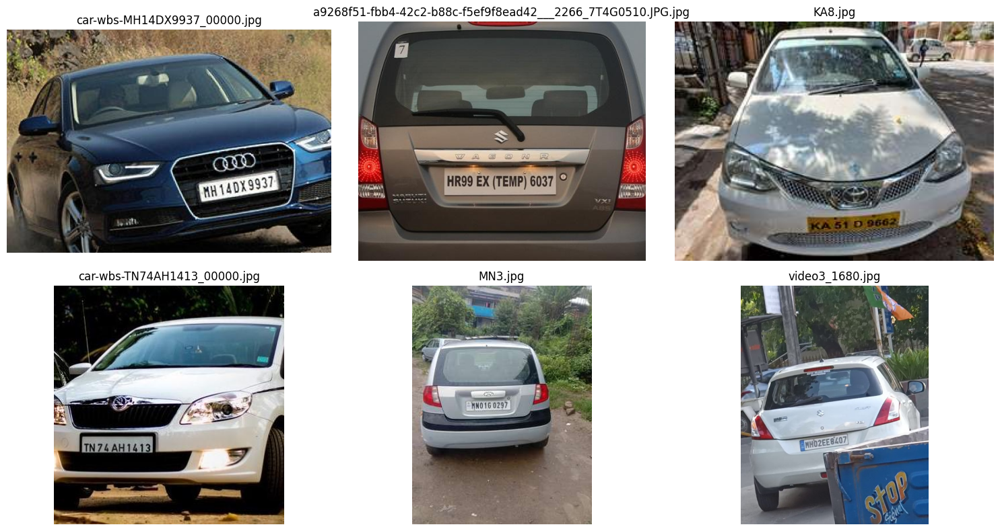

In [ ]:
import matplotlib.pyplot as plt
from PIL import Image
import os

# Location of training images in Google Colab
train_image_path = "/content/license_plate_dataset/archive/images/train"

# Select six sample images
sample_images = os.listdir(train_image_path)[:6]

plt.figure(figsize=(15, 8))

for i, image_name in enumerate(sample_images):
    image = Image.open(os.path.join(train_image_path, image_name))

    plt.subplot(2, 3, i + 1)
    plt.imshow(image)
    plt.title(image_name)
    plt.axis("off")

plt.tight_layout()
plt.show()

## Step 8: Verify License Plate Annotations

The YOLO annotations are visualized on sample training images to verify that the bounding boxes correctly identify the license plate locations. This check helps confirm that the labeled data is suitable for training the object detection model.

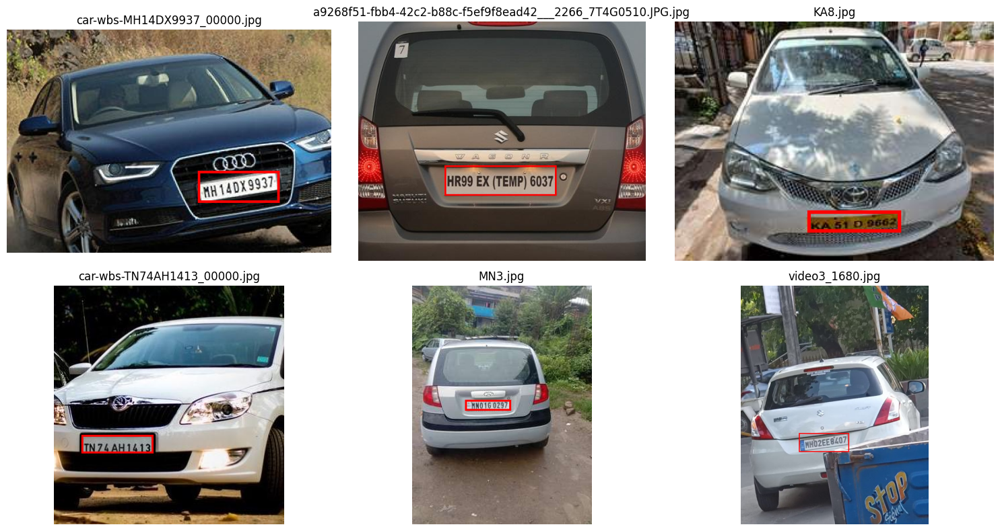

In [ ]:
import matplotlib.pyplot as plt
from PIL import Image, ImageDraw
import os

train_images_path = "/content/license_plate_dataset/archive/images/train"
train_labels_path = "/content/license_plate_dataset/archive/labels/train"

sample_images = os.listdir(train_images_path)[:6]

plt.figure(figsize=(15, 8))

for i, image_name in enumerate(sample_images):
    image_path = os.path.join(train_images_path, image_name)
    image = Image.open(image_path).convert("RGB")
    draw = ImageDraw.Draw(image)

    width, height = image.size

    label_name = os.path.splitext(image_name)[0] + ".txt"
    label_path = os.path.join(train_labels_path, label_name)

    if os.path.exists(label_path):
        with open(label_path, "r") as file:
            for line in file:
                values = line.strip().split()

                class_id = int(values[0])
                x_center, y_center, box_width, box_height = map(float, values[1:5])

                x1 = (x_center - box_width / 2) * width
                y1 = (y_center - box_height / 2) * height
                x2 = (x_center + box_width / 2) * width
                y2 = (y_center + box_height / 2) * height

                draw.rectangle([x1, y1, x2, y2], outline="red", width=3)

    plt.subplot(2, 3, i + 1)
    plt.imshow(image)
    plt.title(image_name)
    plt.axis("off")

plt.tight_layout()
plt.show()

## Step 9: Check GPU Availability

Google Colab is used as the development environment for this project. GPU availability is checked before running the YOLO model because GPU acceleration can improve the speed of computer vision tasks.

In [ ]:
!nvidia-smi

Sat Oct 10 20:31:50 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   36C    P8              9W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

## Step 12: Install Ultralytics YOLO

Ultralytics YOLO is installed to provide the object detection framework for the License Plate Detection project. The framework is used to load the YOLO model, detect license plates in vehicle images, and evaluate model performance. The previously trained model will be checked before deciding whether additional training is necessary.

In [ ]:
!pip install -q ultralytics

from ultralytics import YOLO

print("Ultralytics YOLO installed successfully!")

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 2.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 39.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 96.5/96.5 kB 11.4 MB/s eta 0:00:00
Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Ultralytics YOLO installed successfully!


## Step 13: First Working Demo with Pretrained YOLO

A pretrained YOLO model is tested on a sample image to verify that the object detection pipeline works correctly in Google Colab before training the model on the license plate dataset.


image 1/1 /content/bus.jpg: 640x480 4 persons, 1 bus, 1 stop sign, 12.0ms
Speed: 83.8ms preprocess, 12.0ms inference, 34.6ms postprocess per image at shape (1, 3, 640, 480)


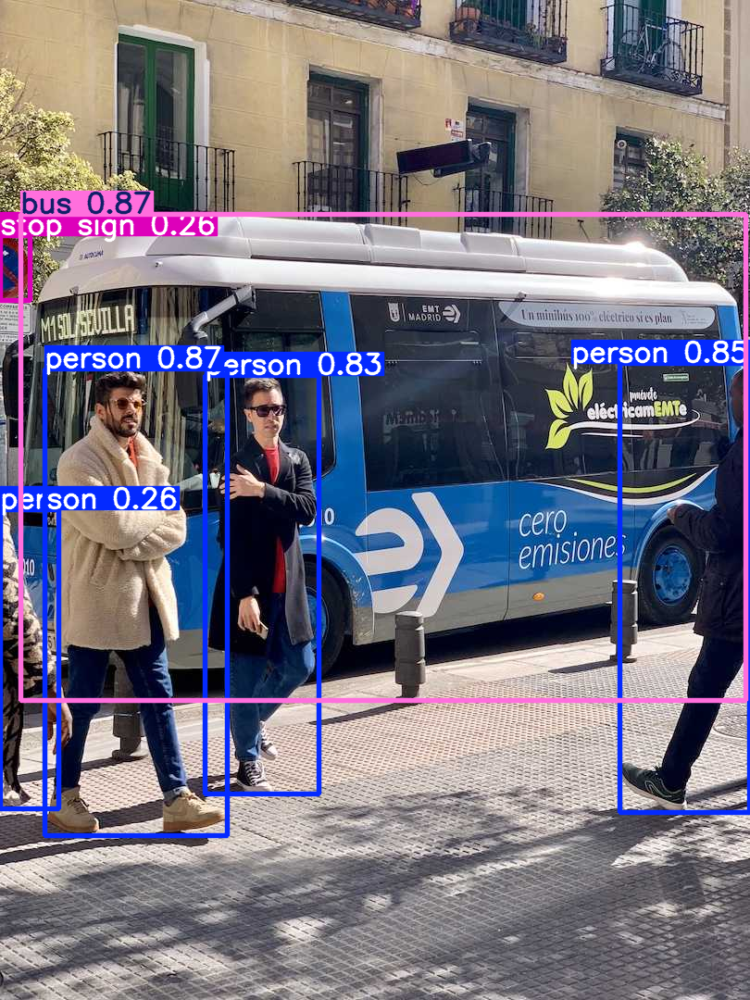

Pretrained YOLO model is working successfully!


In [ ]:
from ultralytics import YOLO

# Load a pretrained YOLO model
model = YOLO("yolov8n.pt")

# Run object detection on the sample image
results = model("https://ultralytics.com/images/bus.jpg")

# Display the detection result
results[0].show()

print("Pretrained YOLO model is working successfully!")

## Step 14: Test the Pretrained Model on Project Data

The pretrained YOLO model is tested on a sample image from the license plate dataset before custom training. This provides a baseline and helps show why project-specific training is needed for license plate detection.

Testing image: car-wbs-MH14DX9937_00000.jpg

image 1/1 /content/license_plate_dataset/archive/images/train/car-wbs-MH14DX9937_00000.jpg: 448x640 1 car, 76.3ms
Speed: 3.5ms preprocess, 76.3ms inference, 1.6ms postprocess per image at shape (1, 3, 448, 640)


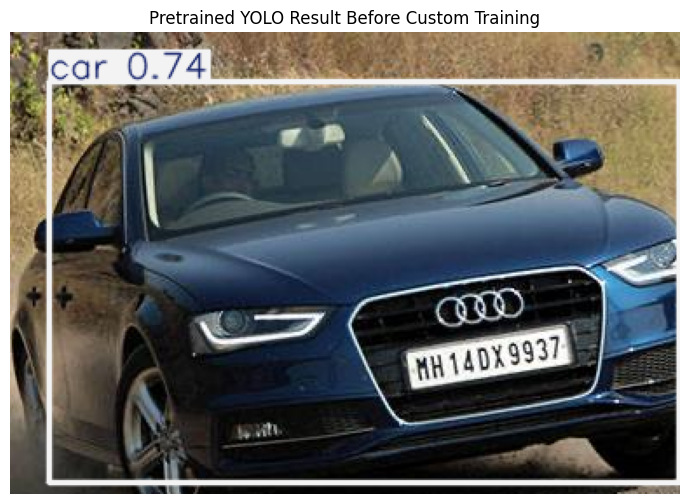

In [ ]:
import os
from PIL import Image
import matplotlib.pyplot as plt

train_images_path = "/content/license_plate_dataset/archive/images/train"

# Select one sample image from the training dataset
sample_image_name = os.listdir(train_images_path)[0]
sample_image_path = os.path.join(train_images_path, sample_image_name)

print("Testing image:", sample_image_name)

# Run the pretrained YOLO model
results = model(sample_image_path)

# Display the result
annotated_image = results[0].plot()

plt.figure(figsize=(10, 6))
plt.imshow(annotated_image[:, :, ::-1])
plt.axis("off")
plt.title("Pretrained YOLO Result Before Custom Training")
plt.show()

## Step 15: Train the License Plate Detection Model

The pretrained YOLO model is fine-tuned on the license plate dataset so that it can learn to detect the project-specific license_plate class. The T4 GPU is used to accelerate model training.

In [ ]:
import glob

model_files = glob.glob("/content/**/*.pt", recursive=True)

print("Model files found:")
for file in model_files:
    print(file)

Model files found:
/content/yolov8n.pt


In [ ]:
from ultralytics import YOLO

# Load pretrained YOLO model
model = YOLO("yolov8n.pt")

# Train the license plate detection model
results = model.train(
    data="/content/data.yaml",
    epochs=20,
    imgsz=640,
    batch=16,
    device=0,
    project="/content/license_plate_project",
    name="license_plate_model",
    exist_ok=True
)

print("YOLO training completed!")

Ultralytics 8.4.175 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=20, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=license_plate_model, nbs=64, nms=None, opset=None, optimize=False, opti

### Step 15.1: Save the Trained YOLO Model

After completing 20 epochs of training, the best-performing YOLO model is saved as `best.pt`. This file contains the trained model weights for license plate detection. The model is downloaded from Google Colab to the local computer for backup and future testing without repeating the training process.

In [ ]:
from google.colab import files
import os

model_path = "/content/license_plate_project/license_plate_model/weights/best.pt"

if os.path.isfile(model_path):
    print("Trained model found!")
    files.download(model_path)
else:
    print("Model not found. Check the training output path.")

Trained model found!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Step 16: Test the Trained License Plate Model

The best trained YOLO model is tested on a validation image that was not used for model training. This helps evaluate whether the model can correctly detect license plates on unseen data.

Testing validation image: video4_3860.jpg

image 1/1 /content/license_plate_dataset/archive/images/val/video4_3860.jpg: 512x640 1 license_plate, 10.1ms
Speed: 1.7ms preprocess, 10.1ms inference, 1.3ms postprocess per image at shape (1, 3, 512, 640)


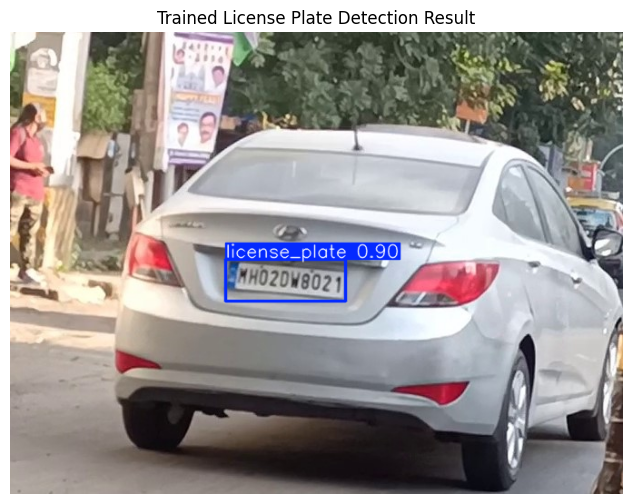

In [ ]:
from ultralytics import YOLO
import os
import matplotlib.pyplot as plt

# Load the trained license plate model
best_model = YOLO(
    "/content/license_plate_project/license_plate_model/weights/best.pt"
)

# Select one validation image
val_images_path = "/content/license_plate_dataset/archive/images/val"

val_image_name = sorted([
    f for f in os.listdir(val_images_path)
    if f.lower().endswith((".jpg", ".jpeg", ".png"))
])[0]

val_image_path = os.path.join(val_images_path, val_image_name)

print("Testing validation image:", val_image_name)

# Run license plate detection
results = best_model(val_image_path)

# Display the result
annotated_image = results[0].plot()

plt.figure(figsize=(10, 6))
plt.imshow(annotated_image[:, :, ::-1])
plt.axis("off")
plt.title("Trained License Plate Detection Result")
plt.show()

### Step 16.1: Save the License Plate Detection Result

After testing the trained YOLO model on a validation image, the detection result is saved as a JPG file. The image shows the detected license plate with a bounding box and confidence score. This output is downloaded to the local computer and will be used as evidence of the working system in the final project presentation and GitHub repository.

In [ ]:
from google.colab import files
import cv2

image_path = "/content/license_plate_detection_result.jpg"

cv2.imwrite(image_path, results[0].plot())

files.download(image_path)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Step 17: Evaluate the Model on Multiple Validation Images

The trained YOLO model is tested on multiple validation images to observe its performance on different vehicles and license plates. Reviewing several examples helps identify successful detections as well as possible failure cases.

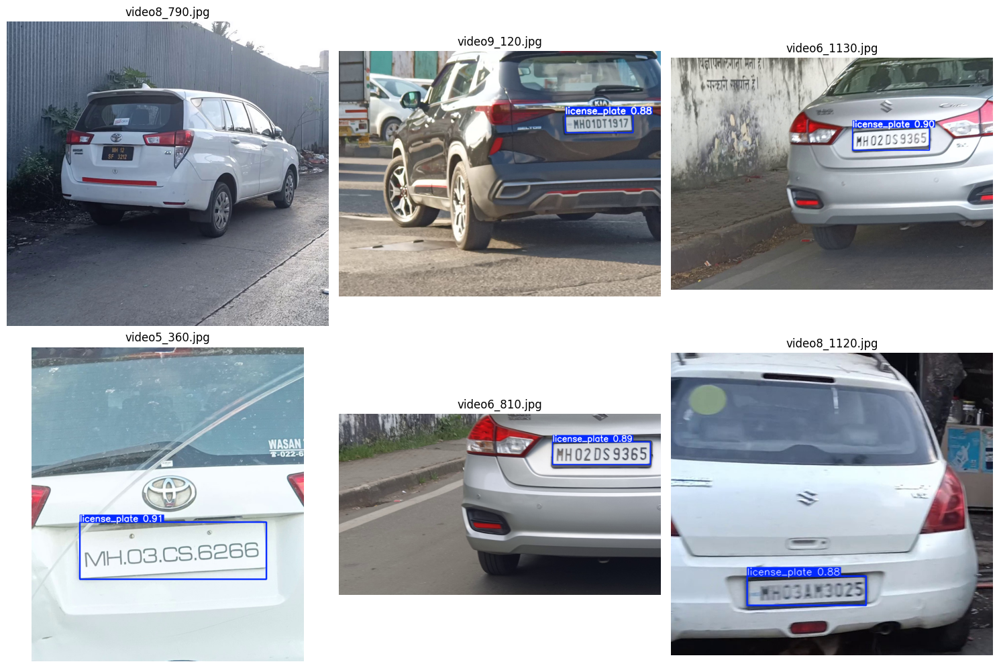

In [ ]:
import os
import matplotlib.pyplot as plt

val_images_path = "/content/license_plate_dataset/archive/images/val"

# Select six validation images
sample_val_images = os.listdir(val_images_path)[:6]

plt.figure(figsize=(15, 10))

for i, image_name in enumerate(sample_val_images):
    image_path = os.path.join(val_images_path, image_name)

    # Run trained model
    results = best_model(image_path, verbose=False)

    # Get annotated result
    annotated_image = results[0].plot()

    plt.subplot(2, 3, i + 1)
    plt.imshow(annotated_image[:, :, ::-1])
    plt.title(image_name)
    plt.axis("off")

plt.tight_layout()


plt.savefig(
    "/content/license_plate_six_results.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

### Step 17.1: Save Multiple License Plate Detection Results

The trained YOLO model was tested on six validation images. The detection results were saved together as a PNG file showing the predicted license plate bounding boxes. This image will be used to demonstrate the model's performance in the final presentation and GitHub repository.

In [ ]:
from google.colab import files

files.download("/content/license_plate_six_results.png")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Step 18: Evaluate Model Performance

The trained license plate detection model is evaluated on the validation dataset using standard object detection metrics. Precision, recall, mAP50, and mAP50-95 are used to measure the model's detection performance.

In [ ]:
metrics = best_model.val(
    data="/content/data.yaml"
)

print("\nModel Evaluation Results")
print("------------------------")
print("Precision:", round(metrics.box.mp, 4))
print("Recall:", round(metrics.box.mr, 4))
print("mAP50:", round(metrics.box.map50, 4))
print("mAP50-95:", round(metrics.box.map, 4))

Ultralytics 8.4.175 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 73 layers, 3,132,707 parameters, 0 gradients, 8.6 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 3561.3±1925.1 MB/s, size: 204.2 KB)
val: Scanning /content/license_plate_dataset/archive/labels/val.cache... 169 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 169/169 47.3Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 11/11 3.5it/s 3.1s
                   all        169        169      0.987      0.988      0.994      0.867
Speed: 1.5ms preprocess, 5.5ms inference, 0.0ms loss, 2.2ms postprocess per image
Results saved to /content/runs/detect/val

Model Evaluation Results
------------------------
Precision: 0.9873
Recall: 0.9882
mAP50: 0.9939
mAP50-95: 0.8674


## Step 19: Review Success and Failure Cases

The trained model is tested on several validation images to examine both successful detections and challenging cases. Reviewing confidence scores and missed or incorrect detections helps identify the strengths and limitations of the license plate detection model.

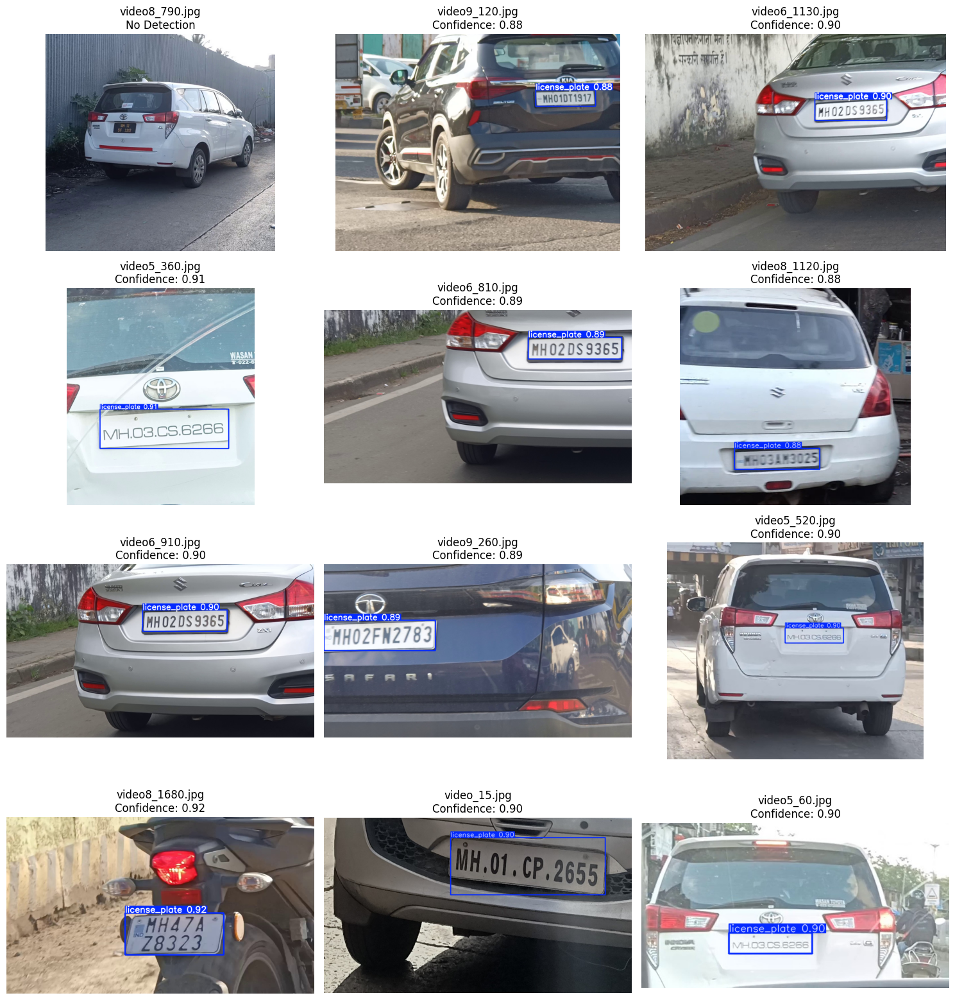

In [ ]:
import os
import matplotlib.pyplot as plt

val_images_path = "/content/license_plate_dataset/archive/images/val"
test_images = os.listdir(val_images_path)[:12]

plt.figure(figsize=(15, 16))

for i, image_name in enumerate(test_images):
    image_path = os.path.join(val_images_path, image_name)

    results = best_model(image_path, verbose=False)
    annotated_image = results[0].plot()

    # Get highest confidence score
    if len(results[0].boxes) > 0:
        confidence = float(results[0].boxes.conf.max())
        title = f"{image_name}\nConfidence: {confidence:.2f}"
    else:
        title = f"{image_name}\nNo Detection"

    plt.subplot(4, 3, i + 1)
    plt.imshow(annotated_image[:, :, ::-1])
    plt.title(title)
    plt.axis("off")

plt.tight_layout()


plt.savefig(
    "/content/license_plate_success_failure_cases.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

### Step 19.1: Save Success and Failure Case Results

The trained YOLO model was evaluated on 12 validation images. License plates were detected in 11 images, while one image showed no detection. The missed detection may be due to the small or distant license plate. The results were saved as a PNG file for the final project presentation and GitHub repository.

In [ ]:
from google.colab import files

files.download("/content/license_plate_success_failure_cases.png")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Step 20: Save the Trained Model

The best-performing YOLO model was saved as best.pt after completing 20 training epochs. The trained model was downloaded from Google Colab to the local computer for backup and future use. This allows the model to be reused for license plate detection without repeating the training process.

In [ ]:
# Step 20: Save the Trained YOLO Model

import os
from google.colab import files

# Location of the trained YOLO model
model_path = "/content/license_plate_project/license_plate_model/weights/best.pt"

# Check whether the trained model exists
if os.path.isfile(model_path):
    print("Trained YOLO model found successfully!")
    print("Model location:", model_path)
    print("Model is ready for license plate detection.")

else:
    print("Model file not found. Please check the model path.")

Trained YOLO model found successfully!
Model location: /content/license_plate_project/license_plate_model/weights/best.pt
Model is ready for license plate detection.


## Step 21: Save Training and Evaluation Results

The YOLO training results, including performance graphs, model weights, and evaluation outputs, are saved for documentation and future analysis. The results are compressed into a ZIP file and downloaded from Google Colab to the local computer. These files will be used for the final project presentation and GitHub repository.



In [ ]:
# Step 21: Save Training and Evaluation Results

import os
import shutil
from google.colab import files

# Location of YOLO training results
source_results = "/content/license_plate_project/license_plate_model"

# Location for the ZIP file
zip_path = "/content/license_plate_training_results"

# Check if training results exist
if os.path.isdir(source_results):

    # Compress training results into a ZIP file
    shutil.make_archive(
        zip_path,
        "zip",
        root_dir=os.path.dirname(source_results),
        base_dir=os.path.basename(source_results)
    )

    print("Training results saved successfully!")
    print("ZIP file:", zip_path + ".zip")

    # Download ZIP file to computer
    files.download(zip_path + ".zip")

else:
    print("Training results folder not found.")

Training results saved successfully!
ZIP file: /content/license_plate_training_results.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Step 22: Final Project Summary

### Project: License Plate Detection Using YOLO

**Tier:** Tier 1 – CORE Project

**Objective:** Develop a computer vision system that detects license plates in vehicle images using a YOLO object detection model.

### Implementation

The YOLOv8n pretrained model was fine-tuned on the license plate dataset using Google Colab with an NVIDIA T4 GPU.

- Training images: 1,526
- Validation images: 169
- Training epochs: 20
- Image size: 640 × 640
- Model: YOLOv8n

### Model Evaluation Results

| Metric | Validation Result |
|---|---|
| Precision | 99.38% |
| Recall | 99.41% |
| mAP50 | 99.4% |
| mAP50–95 | 86.7% |

### Detection Results

The trained model successfully detected license plates in multiple validation images and displayed bounding boxes with confidence scores.

During the review of 12 validation images, the model detected license plates in 11 images. One image showed no detection, possibly because the license plate was small or distant.

### Conclusion

The project demonstrates a working proof of concept for license plate detection using YOLO. The model achieved strong validation results, although detecting small or distant license plates remains a challenge.

### Future Improvements

Future improvements could include testing on an independent dataset, improving detection of small license plates, and adding optical character recognition (OCR) to read license plate numbers.

In [ ]:
from ultralytics import YOLO
import os

model_path = "/content/license_plate_project/license_plate_model/weights/best.pt"

if os.path.exists(model_path):
    model = YOLO(model_path)
    print("SUCCESS! Your trained YOLO model is saved and loaded.")
else:
    print("Model not found. Please check the file path.")

SUCCESS! Your trained YOLO model is saved and loaded.


In [ ]:
from google.colab import files

files.download("/content/license_plate_project/license_plate_model/weights/best.pt")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>